# 4대 RAG 평가자

**이 노트북에서 할 일**

1. 이 챕터 자료 파일에서 평가 사례 세 건을 읽습니다.
2. 네 평가가 사례의 어느 두 칸을 견주는지 표로 적습니다.
3. 평가마다 판정 머리글을 쓰고 평가 모델(judge)에게 판정을 받습니다.
4. 세 사례에 평가 넷을 걸어 점수 표를 만듭니다.
5. 자료 파일에 적힌 판정과 이번 판정을 나란히 봅니다.
6. 기준 답 하나만 바꿔 정답 일치도 판정을 다시 받습니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
평가 모델 `gpt-5.4-mini`에 보내는 요청은 열네 번이고 임베딩 요청은 없습니다.
판정 한 번 보기에 1번, 세 사례에 평가 넷을 거는 데 12번, 값 바꿔 보기에 1번입니다.
예상 비용은 미화 0.05달러 아래이고 실제 청구 금액과는 다를 수 있습니다.

읽는 파일은 이 챕터 자료 파일 하나이고 새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 14초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~8절을 읽습니다.
평가 넷이 견주는 두 칸을 적고 판정 머리글로 판정을 받는 자리입니다.
9~10절은 세 사례의 점수 표를 만들고 파일에 적힌 판정과 견주는 자리입니다.
11절은 값 바꿔 보기이고 실습 시간에 함께 실행합니다.

실습 폴더 `labs/part4/ch15-evaluation-advanced`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

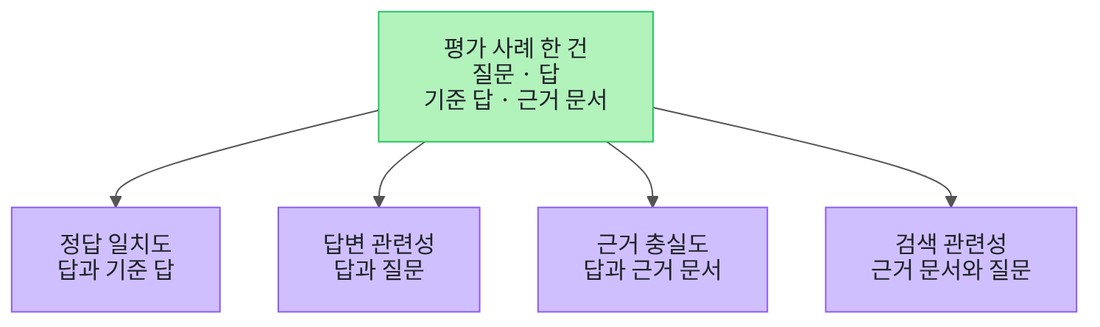

위에서 아래로 읽습니다.
맨 위 초록 상자가 평가 사례 한 건이고 칸 넷을 담고 있습니다.
아래 보라 상자 넷이 평가 모델에게 판정을 받는 평가 넷입니다.
상자마다 둘째 줄이 그 평가가 견주는 두 칸입니다.

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름 세 개를 불러옵니다.
이 절은 도구 파일 `rag_tools.py`에서 가져오는 함수가 없습니다.
앞 절 함수를 다시 쓰지 않고 판정에 쓸 함수를 새로 만들기 때문입니다.

In [2]:
# 자료 읽기·폴더 확인에 쓸 이름과 모델을 준비하는 이름을 불러옵니다
import json
import os

from langchain.chat_models import init_chat_model

print("불러온 이름:", "json", "os", "init_chat_model")

불러온 이름: json os init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 세 개가 보입니다.
이름 `json`은 자료 파일과 모델이 보낸 JSON 글을 읽을 때 씁니다.
이름 `init_chat_model`은 Ch 6부터 쓴 모델 준비 함수입니다.

## 2. 키와 모델 준비

이 절은 평가 모델로 `gpt-5.4-mini`를 부릅니다.
자료 파일의 답을 쓴 모델과 같은 이름입니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 판정 글이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 평가 사례 읽기

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01절과 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch15-evaluation-advanced/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 01절과 같은 방법으로 이 챕터 자료 파일을 읽습니다.
사례 목록 `cases`와 질문 번호 목록 `case_qids`도 01절과 같은 이름입니다.

In [6]:
# 이 챕터 자료 파일을 읽어 평가 사례 목록과 질문 번호 목록을 만듭니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch15-evaluation-advanced/data"
with open(data_path + "/evaluation-cases.json", encoding="utf-8") as file:
    case_file = json.loads(file.read())
cases = case_file["cases"]
case_qids = []
for case in cases:
    case_qids.append(case["qid"])
print("평가 사례 수:", len(cases))
print("평가 사례의 질문 번호:", case_qids)

평가 사례 수: 3
평가 사례의 질문 번호: ['Q002', 'Q006', 'Q090']


**결과 읽기** — 출력 줄 `평가 사례 수: 3`으로 사례는 세 건입니다.
출력 줄 `평가 사례의 질문 번호: ['Q002', 'Q006', 'Q090']`도 01절과 같습니다.

다음 셀은 첫 사례 `Q002`에서 평가에 쓸 칸 넷을 봅니다.
이 절에서 근거 문서는 답을 쓸 때 받은 문서의 본문, 칸 `context`입니다.
본문은 길어서 글자 수만 출력합니다.

In [7]:
# 첫 사례 Q002에서 평가에 쓸 칸 넷을 봅니다(근거 문서 본문은 글자 수만 봅니다)
first_case = cases[0]
print("질문:", first_case["question"])
print("답:", first_case["response"])
print("기준 답:", first_case["reference_answer"])
print("근거 문서:", first_case["retrieved_doc_ids"])
print("근거 문서 글자 수:", len(first_case["context"]))

질문: 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?
답: 도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01]
기준 답: 도서는 한 번에 7권까지 14일 동안 빌릴 수 있습니다.
근거 문서: ['E01']
근거 문서 글자 수: 3020


**결과 읽기** — 출력 줄 `근거 문서: ['E01']`이 답을 쓸 때 받은 문서 ID입니다.
출력 줄 `근거 문서 글자 수: 3020`이 그 문서 본문의 길이입니다.
답은 권수와 기간을 `7권`과 `14일`로 적었고 기준 답도 같은 두 값을 적었습니다.

## 4. 글자 그대로 견주기

답이 기준 답과 맞는지 볼 때 먼저 떠오르는 방법은 두 글을 글자 그대로 견주는 것입니다.
세 사례 모두 그렇게 견주어 봅니다.

In [8]:
# 세 사례마다 답과 기준 답이 글자까지 같은지 봅니다
print("질문 번호 | 답과 기준 답이 글자까지 같은가")
for case in cases:
    same_text = case["response"] == case["reference_answer"]
    print(case["qid"], "|", same_text)

질문 번호 | 답과 기준 답이 글자까지 같은가
Q002 | False
Q006 | False
Q090 | False


**결과 읽기** — 라벨 줄 `질문 번호 | 답과 기준 답이 글자까지 같은가` 아래 세 줄이 모두 `False`입니다.
출력 줄 `Q002 | False`의 답은 권수와 기간이 기준 답과 같지만 글자는 다릅니다.
같은 사실을 다른 말로 적으면 글자 견주기로는 가를 수 없습니다.
그래서 이 절은 글을 읽고 판정하는 평가 모델을 씁니다.

## 5. 평가 넷이 견주는 두 칸

답을 보는 평가는 한 가지가 아닙니다.
이 절은 RAG 답을 네 가지 평가로 봅니다.
네 평가는 사례의 칸 가운데 서로 다른 두 칸을 견줍니다.

다음 셀은 평가마다 견줄 두 칸을 딕셔너리로 적습니다.
안쪽 딕셔너리는 판정 요청 글에 적을 한국어 이름과 사례의 칸 이름을 짝짓습니다.

In [9]:
# 평가 넷마다 견줄 두 칸을 적습니다(판정 요청 글에 적을 이름 → 사례의 칸 이름)
evaluator_pairs = {}
evaluator_pairs["정답 일치도"] = {"답": "response", "기준 답": "reference_answer"}
evaluator_pairs["답변 관련성"] = {"답": "response", "질문": "question"}
evaluator_pairs["근거 충실도"] = {"답": "response", "근거 문서": "context"}
evaluator_pairs["검색 관련성"] = {"근거 문서": "context", "질문": "question"}
print("평가 이름 | 견주는 두 칸")
for name in evaluator_pairs:
    pair_labels = list(evaluator_pairs[name].keys())
    print(name, "|", pair_labels)

평가 이름 | 견주는 두 칸
정답 일치도 | ['답', '기준 답']
답변 관련성 | ['답', '질문']
근거 충실도 | ['답', '근거 문서']
검색 관련성 | ['근거 문서', '질문']


**결과 읽기** — 라벨 줄 `평가 이름 | 견주는 두 칸` 아래 네 줄이 평가 넷입니다.
앞의 세 평가는 `'답'`을 견주고 검색 관련성만 `['근거 문서', '질문']`을 견줍니다.
질문과 근거 문서는 두 평가씩 쓰고 기준 답은 한 평가에서만 씁니다.

네 평가의 영문 이름은 본문 용어 표에 적었습니다.
앞의 둘은 Correctness와 Relevance입니다.
뒤의 둘은 Groundedness와 Retrieval relevance입니다.

다음 셀은 기준 답이 있어야 하는 평가와 답을 보지 않는 평가를 가려 냅니다.

In [10]:
# 기준 답을 쓰는 평가와 답을 보지 않는 평가를 가려 냅니다
needs_reference = []
skips_answer = []
for name in evaluator_pairs:
    fields = list(evaluator_pairs[name].values())
    if "reference_answer" in fields:
        needs_reference.append(name)
    if "response" not in fields:
        skips_answer.append(name)
print("기준 답이 있어야 하는 평가:", needs_reference)
print("답을 보지 않는 평가:", skips_answer)

기준 답이 있어야 하는 평가: ['정답 일치도']
답을 보지 않는 평가: ['검색 관련성']


**결과 읽기** — 출력 줄 `기준 답이 있어야 하는 평가: ['정답 일치도']`로 기준 답을 쓰는 평가는 하나입니다.
출력 줄 `답을 보지 않는 평가: ['검색 관련성']`은 받은 문서와 질문만 봅니다.
기준 답이 없는 사례라도 나머지 세 평가는 걸 수 있습니다.

이 챕터의 기준 답은 교재 작성자가 적은 글입니다.
정답 일치도 점수는 그 글이 맞다는 전제 위에 서 있습니다.
11절 값 바꿔 보기에서 이 전제를 다시 봅니다.

## 6. 판정 머리글 만들기

판정 머리글은 평가 모델에게 판정 기준과 출력 모양을 알려 주는 첫머리 글입니다.
시험지 맨 위에 적힌 채점 기준 안내와 같은 자리입니다.
다음 셀은 평가마다 판정 기준 문장을 한 문장씩 적습니다.

In [11]:
# 평가 넷의 판정 기준 문장을 한 문장씩 적습니다(맞으면 1, 아니면 0)
judge_rules = {}
judge_rules["정답 일치도"] = "답이 기준 답과 같은 사실을 말하면 1, 아니면 0을 판정하세요."
judge_rules["답변 관련성"] = "답이 질문에 바로 답하면 1, 아니면 0을 판정하세요."
judge_rules["근거 충실도"] = "답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요."
judge_rules["검색 관련성"] = "근거 문서에 질문과 관련된 내용이 있으면 1, 아니면 0을 판정하세요."
print("판정 기준 문장:")
for name in judge_rules:
    print(name, "|", judge_rules[name])

판정 기준 문장:
정답 일치도 | 답이 기준 답과 같은 사실을 말하면 1, 아니면 0을 판정하세요.
답변 관련성 | 답이 질문에 바로 답하면 1, 아니면 0을 판정하세요.
근거 충실도 | 답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요.
검색 관련성 | 근거 문서에 질문과 관련된 내용이 있으면 1, 아니면 0을 판정하세요.


**결과 읽기** — 라벨 줄 `판정 기준 문장:` 아래 네 줄이 평가 넷의 기준입니다.
네 문장 모두 맞으면 1, 아니면 0을 판정하라고 말합니다.
문장 앞부분의 조건만 평가마다 다릅니다.

교재 제작 기록(`prepare_runs.py`)에서 자료 파일의 판정 글을 받을 때 쓴 기준 문장을 확인했습니다.
근거 충실도 문장은 그 문장과 거의 같고, 그때 문장은 답을 「응답」이라고 불렀습니다.
네 문장 어디에도 모른다고 답한 경우를 어떻게 셀지는 적혀 있지 않습니다.

다음 셀은 네 문장 뒤에 같은 출력 모양 한 줄을 붙이고 판 이름을 적습니다.
출력 모양은 점수 `score`와 까닭 `reason` 두 칸이 든 JSON 글입니다.
자료 파일의 판정 글 칸 `judge_raw`와 같은 모양이라 나란히 놓을 수 있습니다.

In [12]:
# 네 기준 문장 뒤에 같은 출력 모양 한 줄을 붙여 판정 머리글 넷을 만들고 판 이름을 적습니다
judge_version = "rag-judge-v1.0.0"
output_rule = 'JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.'
judge_heads = {}
for name in judge_rules:
    judge_heads[name] = judge_rules[name] + "\n" + output_rule
print("판정 머리글 판:", judge_version)
print("근거 충실도 판정 머리글:")
print(judge_heads["근거 충실도"])

판정 머리글 판: rag-judge-v1.0.0
근거 충실도 판정 머리글:
답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요.
JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.


**결과 읽기** — 출력 줄 `판정 머리글 판: rag-judge-v1.0.0`이 이 절 판정 머리글의 판 이름입니다.
라벨 줄 `근거 충실도 판정 머리글:` 아래 두 줄이 모델이 받을 첫머리 글입니다.
둘째 줄의 출력 모양은 네 평가가 모두 같습니다.

판 이름을 붙이는 까닭은 머리글을 고치면 판정도 달라질 수 있기 때문입니다.
어느 머리글로 받은 판정인지 적어 두어야 나중에 견줄 수 있습니다.
자료 파일의 사례에도 판 이름 칸 `judge_prompt_version`이 있습니다.

다음 셀은 판정 머리글 뒤에 견줄 두 칸을 이어 붙이는 함수를 만듭니다.

In [13]:
# 판정 머리글 뒤에 견줄 두 칸을 이름과 함께 이어 붙여 판정 요청 글 하나를 만듭니다
def build_judge_prompt(judge_head, pair, case):
    prompt_text = judge_head + "\n\n"
    for label in pair:
        field = pair[label]
        prompt_text = prompt_text + label + ":\n" + case[field] + "\n\n"
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_judge_prompt`는 판정 머리글과 두 칸 짝과 사례 한 건을 받습니다.
짝의 한국어 이름을 한 줄에 적고 그 칸의 글을 다음 줄에 붙입니다.
노트북의 다른 이름을 읽지 않고 필요한 값은 모두 인자로 받습니다.

다음 셀은 사례 Q002의 정답 일치도 판정 요청 글을 만들어 그대로 출력합니다.
아직 모델을 부르지 않습니다.

In [14]:
# 사례 Q002의 정답 일치도 판정 요청 글을 만들어 그대로 출력합니다(아직 모델을 부르지 않습니다)
correct_head = judge_heads["정답 일치도"]
correct_pair = evaluator_pairs["정답 일치도"]
first_prompt = build_judge_prompt(correct_head, correct_pair, first_case)
print("판정 요청 글:")
print(first_prompt)
print("판정 요청 글자 수:", len(first_prompt))

판정 요청 글:
답이 기준 답과 같은 사실을 말하면 1, 아니면 0을 판정하세요.
JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.

답:
도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01]

기준 답:
도서는 한 번에 7권까지 14일 동안 빌릴 수 있습니다.


판정 요청 글자 수: 175


**결과 읽기** — 라벨 줄 `판정 요청 글:` 아래가 모델이 받을 글 전체입니다.
맨 위 두 줄이 판정 머리글이고 그 아래 `답:`과 `기준 답:`이 견줄 두 칸입니다.
출력 줄 `판정 요청 글자 수: 175`로 요청 글은 짧습니다.
질문과 근거 문서는 이 글에 들어가지 않습니다.

## 7. 판정 한 번 받기

이제 그 글을 평가 모델에 보냅니다.
모델이 보낸 글을 먼저 그대로 보고 그다음에 읽습니다.

In [15]:
# 그 글을 평가 모델에 보내고 받은 글을 그대로 출력합니다(모델 요청 1번)
first_reply = model.invoke(first_prompt)
print("모델이 보낸 글:")
print(first_reply.text)

모델이 보낸 글:
{"score":1,"reason":"두 답변 모두 도서를 한 번에 7권까지 14일 동안 빌릴 수 있다고 같은 사실을 말합니다."}


**결과 읽기** — 라벨 줄 `모델이 보낸 글:` 아래 한 줄이 평가 모델이 보낸 글입니다.
중괄호로 시작하는 JSON 글이고 칸 `"score"`와 `"reason"`이 들어 있습니다.
머리글이 적은 출력 모양 그대로입니다.

이번 실행에서 점수 칸은 1이었습니다.
까닭 글은 모델이 쓴 문장이라 실행마다 달라질 수 있습니다.

다음 셀은 받은 JSON 글을 01절에서 쓴 `json.loads`로 딕셔너리로 읽습니다.
01절에서는 파일 글을 읽었고 이번에는 모델이 보낸 글을 읽습니다.

In [16]:
# 받은 JSON 글을 딕셔너리로 읽고 점수와 까닭을 따로 꺼냅니다
first_verdict = json.loads(first_reply.text)
print("점수:", first_verdict["score"])
print("점수의 자료형:", type(first_verdict["score"]))
print("까닭:", first_verdict["reason"])

점수: 1
점수의 자료형: <class 'int'>
까닭: 두 답변 모두 도서를 한 번에 7권까지 14일 동안 빌릴 수 있다고 같은 사실을 말합니다.


**결과 읽기** — 출력 줄 `점수의 자료형: <class 'int'>`로 점수는 글이 아니라 정수입니다.
JSON 글 안의 숫자는 `json.loads`를 거치면 정수로 읽힙니다.
그래서 뒤에서 점수를 바로 표에 모을 수 있습니다.

이번 실행의 줄 `점수: 1`은 두 글이 같은 사실을 말한다는 판정입니다.
까닭 줄은 모델이 쓴 한 문장이라 실행마다 달라질 수 있습니다.

다음 셀은 요청 글 하나를 보내고 JSON 글을 읽는 두 줄을 함수로 묶습니다.
모델도 인자로 받아 어느 모델로 판정했는지 드러나게 합니다.

In [17]:
# 판정 요청 글 하나를 평가 모델에 보내고 받은 JSON 글을 딕셔너리로 읽습니다
def judge_once(judge_model, prompt_text):
    reply = judge_model.invoke(prompt_text)
    verdict = json.loads(reply.text)
    return verdict

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `judge_once`는 평가 모델과 판정 요청 글을 받아 판정 딕셔너리 하나를 만듭니다.
받은 글이 JSON 모양이 아니면 `json.loads`에서 멈춥니다.
이번 실행에서는 그런 글을 받지 않았습니다.

## 8. 한 사례에 평가 넷 걸기

다음 셀은 사례 한 건에 평가 넷을 차례로 거는 함수입니다.
부를 때마다 모델 요청이 네 번 나갑니다.

In [18]:
# 사례 한 건에 평가 넷을 차례로 걸어 평가 이름별 판정을 모읍니다(부를 때마다 모델 요청 4번)
def judge_case(judge_model, heads, pairs, case):
    verdicts = {}
    for name in pairs:
        prompt_text = build_judge_prompt(heads[name], pairs[name], case)
        verdicts[name] = judge_once(judge_model, prompt_text)
    return verdicts

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `judge_case`는 평가 이름마다 요청 글을 만들고 `judge_once`를 부릅니다.
판정은 평가 이름을 키로 삼은 딕셔너리에 모입니다.

다음 셀은 사례 Q002에 이 함수를 겁니다.
7절에서 받은 정답 일치도 판정도 같은 요청 글로 한 번 더 받습니다.

In [19]:
# 사례 Q002에 평가 넷을 걸고 점수와 까닭을 출력합니다(모델 요청 4번)
first_verdicts = judge_case(model, judge_heads, evaluator_pairs, first_case)
print("평가 이름 | 점수 | 까닭")
for name in first_verdicts:
    verdict = first_verdicts[name]
    print(name, "|", verdict["score"], "|", verdict["reason"])

평가 이름 | 점수 | 까닭
정답 일치도 | 1 | 두 답변 모두 도서를 한 번에 7권까지 14일 동안 빌릴 수 있다고 같은 사실을 말합니다.
답변 관련성 | 1 | 질문이 도서의 최대 대출 권수와 대출 기간을 직접 묻고, 답이 그 정보를 바로 제시합니다.
근거 충실도 | 1 | 근거 문서 4번 자료 대출에 도서는 한 번에 7권까지, 대출 기간은 14일이라고 명시되어 있습니다.
검색 관련성 | 1 | 근거 문서의 자료 대출 항목에 한 번에 도서 7권까지, 대출 기간은 14일이라고 명시되어 있습니다.


**결과 읽기** — 라벨 줄 `평가 이름 | 점수 | 까닭` 아래 네 줄이 사례 Q002의 판정입니다.
평가마다 점수와 까닭이 한 줄씩 있습니다.
까닭을 읽으면 평가마다 무엇을 보고 판정했는지 드러납니다.

이번 실행에서는 네 점수가 모두 1이었습니다.
근거 충실도 까닭은 근거 문서의 자료 대출 항목을 짚었습니다.
검색 관련성 까닭은 답을 말하지 않고 근거 문서의 내용만 짚었습니다.
까닭 글은 실행마다 문장이 달라질 수 있습니다.

## 9. 세 사례의 점수 표

나머지 두 사례 Q006과 Q090에도 같은 평가 넷을 겁니다.
머리글과 두 칸 짝은 그대로 두고 사례만 바꿉니다.

In [20]:
# 나머지 두 사례에도 같은 평가 넷을 걸어 질문 번호별로 모읍니다(모델 요청 8번)
all_verdicts = {}
all_verdicts["Q002"] = first_verdicts
for case in cases[1:]:
    all_verdicts[case["qid"]] = judge_case(model, judge_heads, evaluator_pairs, case)
judged_qids = list(all_verdicts.keys())
print("판정을 모은 사례:", judged_qids)

판정을 모은 사례: ['Q002', 'Q006', 'Q090']


**결과 읽기** — 출력 줄 `판정을 모은 사례: ['Q002', 'Q006', 'Q090']`으로 세 사례의 판정을 모두 모았습니다.
이 셀에서 모델 요청이 여덟 번 나갔습니다.
사례 Q002는 앞 셀에서 받은 판정을 그대로 넣었습니다.

다음 셀은 세 사례의 점수만 뽑아 표로 출력합니다.

In [21]:
# 세 사례의 점수를 평가 이름 차례대로 모아 한 줄씩 출력합니다
print("질문 번호 | 정답 일치도·답변 관련성·근거 충실도·검색 관련성 점수")
for qid in all_verdicts:
    score_list = []
    for name in evaluator_pairs:
        score_list.append(all_verdicts[qid][name]["score"])
    print(qid, "|", score_list)

질문 번호 | 정답 일치도·답변 관련성·근거 충실도·검색 관련성 점수
Q002 | [1, 1, 1, 1]
Q006 | [1, 1, 1, 1]
Q090 | [1, 0, 0, 0]


**결과 읽기** — 라벨 줄 `질문 번호 | 정답 일치도·답변 관련성·근거 충실도·검색 관련성 점수` 아래 세 줄이 점수 표입니다.
목록 하나에 점수 넷이 라벨 줄의 평가 차례대로 들어 있습니다.

이번 실행에서 `Q002`와 `Q006`은 `[1, 1, 1, 1]`이었습니다.
질문 `Q090`은 `[1, 0, 0, 0]`으로 정답 일치도만 1이었습니다.
사례 Q090은 기준 답도 「확인할 수 없다」인 사례입니다.
나머지 세 판정이 왜 0인지는 10절에서 까닭을 읽습니다.

## 10. 파일에 적힌 판정과 견주기

자료 파일의 칸 `judge_raw`에는 근거 충실도 판정 글이 적혀 있습니다.
실습 폴더를 만들 때 한 번 받아 둔 글입니다.
그 점수와 이번에 받은 근거 충실도 점수를 나란히 놓습니다.

In [22]:
# 자료 파일에 적힌 근거 충실도 판정 글을 읽어 이번 근거 충실도 점수와 나란히 놓습니다
print("질문 번호 | 파일에 적힌 점수 | 이번 점수")
for case in cases:
    stored_verdict = json.loads(case["judge_raw"])
    now_verdict = all_verdicts[case["qid"]]["근거 충실도"]
    print(case["qid"], "|", stored_verdict["score"], "|", now_verdict["score"])

질문 번호 | 파일에 적힌 점수 | 이번 점수
Q002 | 1 | 1
Q006 | 1 | 1
Q090 | 0 | 0


**결과 읽기** — 라벨 줄 `질문 번호 | 파일에 적힌 점수 | 이번 점수` 아래 세 줄이 근거 충실도 점수입니다.
가운데가 칸 `judge_raw`에서 읽은 점수이고 오른쪽이 이번에 받은 점수입니다.

이번 실행에서는 세 줄 모두 두 점수가 같았습니다.
줄 `Q090 | 0 | 0`으로 사례 Q090은 두 판정 모두 0입니다.
다음 셀에서 두 판정이 같은 조건에서 나왔는지 봅니다.

In [23]:
# 두 판정이 어떤 조건에서 나왔는지 기록된 값을 나란히 봅니다
ground_labels = list(evaluator_pairs["근거 충실도"].keys())
print("파일에 적힌 판정의 모델:", cases[0]["judge_model"])
print("파일에 적힌 판정 머리글 판:", cases[0]["judge_prompt_version"])
print("이번 판정의 모델:", model.model_name)
print("이번 판정 머리글 판:", judge_version)
print("이번 근거 충실도 판정에 넣은 칸:", ground_labels)

파일에 적힌 판정의 모델: gpt-5.4-mini
파일에 적힌 판정 머리글 판: groundedness-v1.0.0
이번 판정의 모델: gpt-5.4-mini
이번 판정 머리글 판: rag-judge-v1.0.0
이번 근거 충실도 판정에 넣은 칸: ['답', '근거 문서']


**결과 읽기** — 출력 줄 `파일에 적힌 판정의 모델: gpt-5.4-mini`와 `이번 판정의 모델: gpt-5.4-mini`는 같은 이름입니다.
출력 줄 `파일에 적힌 판정 머리글 판: groundedness-v1.0.0`과 `이번 판정 머리글 판: rag-judge-v1.0.0`은 다릅니다.
출력 줄 `이번 근거 충실도 판정에 넣은 칸: ['답', '근거 문서']`로 이번에는 두 칸만 넣었습니다.

교재 제작 기록(`prepare_runs.py`)에 따르면 자료 파일의 판정은 질문·근거·응답 세 칸을 넣은 머리글로 받은 글입니다.
그때는 추론 설정을 따로 적지 않았고 이번에는 `none`으로 적었습니다.
머리글·넣은 칸·설정·날짜가 모두 다릅니다.
그래서 두 점수가 같아도 같은 판정을 두 번 받았다고 말할 수는 없습니다.

다음 셀은 사례 Q090의 답과 기준 답, 두 판정의 까닭을 나란히 봅니다.

In [24]:
# 사례 Q090의 답과 기준 답, 파일에 적힌 판정의 까닭과 이번 판정 넷을 나란히 출력합니다
last_case = cases[2]
last_stored = json.loads(last_case["judge_raw"])
print("답:", last_case["response"])
print("기준 답:", last_case["reference_answer"])
print("파일에 적힌 근거 충실도 까닭:", last_stored["reason"])
print("이번 판정 | 점수 | 까닭")
for name in all_verdicts["Q090"]:
    verdict = all_verdicts["Q090"][name]
    print(name, "|", verdict["score"], "|", verdict["reason"])

답: 제공된 근거에는 “입회인”이 누구인지에 대한 내용이 별도로 기재되어 있지 않아 알 수 없습니다. [H01]
기준 답: 제공된 본문에는 입회인 정보가 없어 확인할 수 없습니다.
파일에 적힌 근거 충실도 까닭: 근거 문서에는 계약 당사자와 서명일은 있으나 입회인에 대한 별도 기재가 없어 알 수 없습니다.
이번 판정 | 점수 | 까닭
정답 일치도 | 1 | 두 답변 모두 본문에 입회인 정보가 없어 확인할 수 없다고 말합니다.
답변 관련성 | 0 | 답변이 입회인이 누구인지 직접 제시하지 않고 알 수 없다고만 했습니다.
근거 충실도 | 0 | 근거 문서에는 ‘입회인’에 대한 언급이나 그가 누구인지 설명하는 내용이 없어 답변을 뒷받침하지 못합니다.
검색 관련성 | 0 | 제시된 계약서에는 갑과 을만 명시되어 있고 입회인에 대한 언급은 없습니다.


**결과 읽기** — 출력 줄 `답:`과 `기준 답:`은 둘 다 입회인 정보가 없어 알 수 없다는 뜻입니다.
출력 줄 `파일에 적힌 근거 충실도 까닭:`도 근거 문서에 입회인 기재가 없다고 적었습니다.
라벨 줄 `이번 판정 | 점수 | 까닭` 아래 네 줄이 이번에 받은 판정입니다.

이번 실행에서 정답 일치도만 1이었고 두 글이 같은 뜻이라고 적었습니다.
나머지 셋은 0이었습니다.
근거 충실도와 검색 관련성 까닭은 문서에 입회인 언급이 없다는 점을 짚었습니다.
답은 바로 그 사실을 말했는데도 근거 충실도는 0이었습니다.
답변 관련성 까닭은 누가 입회인인지 직접 답하지 않았다고 적었습니다.

판정 기준 문장은 모른다고 답한 경우를 어떻게 셀지 적지 않았습니다.
이번 0점이 그 때문인지는 이 절에서 확인하지 않았습니다.
어느 판정이 맞는지도 여기서 정하지 않습니다.
판정 머리글을 바꾸어 보는 일은 03절에서 합니다.

## 11. 값 바꿔 보기 · 기준 답을 바꾸면

바꿀 값은 사례 Q002의 기준 답 하나입니다.
권수와 기간을 틀리게 적은 글로 바꾸고 답과 판정 머리글은 그대로 둡니다.
원래 사례를 고치지 않으려고 `copy()`로 복사본을 만들어 바꿉니다.

실행 전에 예상해 봅니다.
답은 그대로인데 기준 답이 틀렸으니 정답 일치도는 0이 나올 것입니다.

In [25]:
# 바꿀 값은 사례 Q002의 기준 답 하나입니다(권수와 기간을 틀리게 적은 글, 모델 요청 1번)
changed_case = first_case.copy()
changed_case["reference_answer"] = "도서는 한 번에 5권까지 7일 동안 빌릴 수 있습니다."
changed_prompt = build_judge_prompt(correct_head, correct_pair, changed_case)
changed_verdict = judge_once(model, changed_prompt)
print("바꾼 기준 답:", changed_case["reference_answer"])
print("답:", changed_case["response"])
print("점수:", changed_verdict["score"])
print("까닭:", changed_verdict["reason"])

바꾼 기준 답: 도서는 한 번에 5권까지 7일 동안 빌릴 수 있습니다.
답: 도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01]
점수: 0
까닭: 대출 가능 권수와 기간이 기준 답과 다릅니다.


**결과 읽기** — 출력 줄 `바꾼 기준 답: 도서는 한 번에 5권까지 7일 동안 빌릴 수 있습니다.`가 바꾼 값입니다.
출력 줄 `답: 도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01]`은 바꾸기 전과 같은 글입니다.

이번 실행에서 점수는 0이었고 까닭은 권수와 기간이 기준 답과 다르다고 적었습니다.
예상대로 답은 그대로인데 정답 일치도가 1에서 0으로 바뀌었습니다.
기준 답이 틀리면 맞는 답도 정답 일치도 0을 받았습니다.

다음 셀은 같은 복사본으로 근거 충실도 판정 요청 글을 만듭니다.
기준 답을 바꾸기 전과 뒤의 요청 글이 같은지 봅니다.
이 셀은 모델을 부르지 않습니다.

In [26]:
# 기준 답을 바꾸기 전과 뒤의 근거 충실도 판정 요청 글이 같은지 봅니다(모델을 부르지 않습니다)
ground_head = judge_heads["근거 충실도"]
ground_pair = evaluator_pairs["근거 충실도"]
before_prompt = build_judge_prompt(ground_head, ground_pair, first_case)
after_prompt = build_judge_prompt(ground_head, ground_pair, changed_case)
print("두 요청 글이 같은가:", before_prompt == after_prompt)
print("바꾼 기준 답이 요청 글에 들어 있는가:", changed_case["reference_answer"] in after_prompt)

두 요청 글이 같은가: True
바꾼 기준 답이 요청 글에 들어 있는가: False


**결과 읽기** — 출력 줄 `두 요청 글이 같은가: True`로 근거 충실도 요청 글은 바뀌지 않았습니다.
출력 줄 `바꾼 기준 답이 요청 글에 들어 있는가: False`도 같은 뜻입니다.
근거 충실도 요청 글에는 기준 답이 들어가지 않습니다.
그래서 기준 답을 틀리게 바꿔도 근거 충실도 요청은 그대로입니다.

## 정리

1. 네 평가는 사례의 서로 다른 두 칸을 견주고 기준 답이 있어야 하는 평가는 정답 일치도 하나였습니다.
2. 새 커널 두 번 모두 Q002·Q006은 네 점수가 1이었고 Q090은 정답 일치도만 1이었습니다.
3. 근거 충실도 점수는 파일에 적힌 판정과 같았지만 머리글·넣은 칸·설정이 달라 같은 판정이라 할 수 없습니다.

03절에서는 판정 머리글을 바꾸면 같은 답의 판정이 달라지는지 봅니다.